# ODIR-5K: Normal vs Abnormal Fundus Classification
### PyTorch · EfficientNet-B0 (ImageNet-pretrained) · per-eye labels · patient-level split

This notebook classifies each retinal fundus image in ODIR-5K as **Normal (N)** or **Abnormal (X)**. That is the same task as the original project, but here the labels come from each eye's own diagnostic keywords instead of KMeans colour clusters.

**How to run on Kaggle**
1. *File → Import Notebook* and upload this `.ipynb`.
2. *Data*: the notebook uses [andrewmvd/ocular-disease-recognition-odir5k](https://www.kaggle.com/datasets/andrewmvd/ocular-disease-recognition-odir5k). If it is attached with *Add Input*, it is used directly. If not, the notebook fetches it itself with `kagglehub`, which needs Internet on (step 4).
3. *Settings → Accelerator*: **GPU T4 x2**. The notebook uses one of the two GPUs. Do **not** choose **GPU P100**: Kaggle's current PyTorch no longer supports it and fails with *"no kernel image is available"*.
4. *Settings → Internet*: **On**. This is needed to download the ImageNet weights, and the dataset if it isn't attached. Kaggle asks you to verify your phone number once before it allows GPU and Internet.
5. *Run All*. Training takes about 35–50 minutes on one T4. If you get a CUDA *out of memory* error, set `BATCH_SIZE = 24` in the config cell.

**Version 2.** This version changes two things from the first run:
- Input size goes from 384px to **512px**, the full resolution of the preprocessed images, so small lesions such as microaneurysms stay visible.
- Regularisation is **stronger**, to close the gap between training and validation: heavier augmentation including random erasing, mixup, dropout 0.5 and weight decay 0.05.

It also reports a threshold chosen for **85% sensitivity**. Version 1 test results at threshold 0.5, as a baseline: ROC-AUC 0.846, accuracy 76.1%, sensitivity 73.0%, specificity 80.0%. Training AUC reached 0.97 while validation stayed around 0.83.

Everything it produces is saved to `/kaggle/working`: `best_model.pt`, `odir_effnetb0_final.pt`, `test_predictions.csv`, `test_metrics.csv`, and the plots.

**Pipeline**
1. Build one row per eye image, labelled from **that eye's** keywords.
2. Split 60 / 20 / 20 **by patient**, so no patient appears in two splits.
3. Augment the images and fine-tune EfficientNet-B0 in two stages, with mixed precision and early stopping on validation AUC.
4. Choose the decision threshold on validation, then report metrics on the untouched test set.
5. Use Grad-CAM to see where the model looks, and `predict()` to classify new images.

**What changed compared with the original notebook**

| | Original | This notebook |
|---|---|---|
| Labels | KMeans clusters of pixel colours | Each eye's diagnostic keywords |
| Rows | `drop_duplicates('ID')` mixed left and right eyes | Every usable left **and** right image |
| Split | Random by image (both eyes of a patient can leak across splits) | Grouped by patient ID, stratified by class |
| Output / loss | 2 sigmoid units + binary cross-entropy | 2 logits + cross-entropy (softmax) |
| Model | Small CNN trained from scratch | EfficientNet-B0 pretrained on ImageNet |
| Metrics | Accuracy | ROC-AUC, PR-AUC, F1, sensitivity, specificity, confusion matrix |

## 1. Setup

In [1]:
import os, re, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, f1_score,
                             accuracy_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')

In [2]:
# ----------------------------- Config -----------------------------
DATASET     = 'andrewmvd/ocular-disease-recognition-odir5k'   # kaggle.com/datasets/andrewmvd/ocular-disease-recognition-odir5k
DATA_DIR    = Path('/kaggle/input/ocular-disease-recognition-odir5k')   # where "Add Input" mounts it
OUT_DIR     = Path('/kaggle/working')
IMG_SIZE    = 512     # full resolution of the preprocessed images (v1 used 384)
BATCH_SIZE  = 32
NUM_WORKERS = min(4, os.cpu_count() or 2)
SEED        = 42

FROZEN_EPOCHS   = 3     # stage 1: backbone frozen, train only the new classifier head
FINETUNE_EPOCHS = 30    # stage 2: everything trainable (early stopping usually ends it sooner)
PATIENCE        = 7     # stop after this many epochs without a better validation AUC
LR_HEAD         = 1e-3
LR_BACKBONE     = 1e-4
WEIGHT_DECAY    = 0.05  # v1: 1e-4

# Regularisation (v2)
DROPOUT     = 0.5       # before the final layer (v1: 0.3)
MIXUP_ALPHA = 0.4       # mixup blends pairs of training images and their labels
MIXUP_PROB  = 0.5       # fraction of training batches that get mixup

TARGET_SENSITIVITY = 0.85   # also report a threshold that catches 85% of abnormal eyes on validation

CLASS_NAMES = ['Normal', 'Abnormal']   # target 0 = Normal (N), 1 = Abnormal (X)

In [3]:
def find_dataset():
    """Use the dataset if it is attached (any folder under /kaggle/input); otherwise fetch it with kagglehub."""
    if (DATA_DIR / 'full_df.csv').exists():
        return DATA_DIR
    root = Path('/kaggle/input')
    hits = sorted(root.rglob('full_df.csv')) if root.exists() else []
    if hits:
        return hits[0].parent
    print(f'Dataset not attached - fetching {DATASET} with kagglehub (may take a few minutes) ...')
    try:
        import kagglehub
        path = Path(kagglehub.dataset_download(DATASET))
    except Exception as e:
        raise RuntimeError(f'Could not fetch {DATASET}. Turn on Settings -> Internet and run again, '
                           'or attach the dataset with "Add Input".') from e
    hits = sorted(path.rglob('full_df.csv'))
    if not hits:
        raise FileNotFoundError(f'full_df.csv not found in {path}. Is {DATASET} the right dataset?')
    return hits[0].parent

DATA_DIR = find_dataset()
CSV_PATH = DATA_DIR / 'full_df.csv'
IMG_DIR  = DATA_DIR / 'preprocessed_images'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(SEED)
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'          # mixed precision on GPU
torch.backends.cudnn.benchmark = True

if USE_AMP:   # fail early with a clear message if this PyTorch build can't run on the GPU (e.g. P100)
    try:
        torch.ones(1, device=device).add_(1)
        torch.cuda.synchronize()
    except RuntimeError as e:
        raise RuntimeError(f'PyTorch {torch.__version__} cannot run on {torch.cuda.get_device_name(0)}. '
                           'Switch Settings -> Accelerator to "GPU T4 x2" and run again.') from e

print('torch', torch.__version__, '| device:', device,
      f'({torch.cuda.get_device_name(0)})' if USE_AMP else '- NO GPU: turn on the accelerator in Settings')
print('data :', DATA_DIR)
print('out  :', OUT_DIR)

Dataset not attached - fetching andrewmvd/ocular-disease-recognition-odir5k with kagglehub (may take a few minutes) ...
torch 2.11.0+cu128 | device: cuda (Tesla T4)
data : /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k
out  : /kaggle/working


## 2. Per-eye labels

`full_df.csv` has one row per image, but its `N … O`, `labels` and `target` columns describe the **patient**, meaning both eyes together. For a patient with cataract in the left eye only, `N = 0`, so the healthy right eye would wrongly be called abnormal. Each image is therefore labelled from **its own eye's** keyword column:

- **Normal (0):** the only diagnosis is `normal fundus`. Photo artifacts such as `lens dust` are ignored.
- **Abnormal (1):** at least one disease keyword, for example diabetic retinopathy, glaucoma, cataract, AMD, hypertensive retinopathy, myopia, drusen, or laser spots.
- **Dropped:** `low image quality`, `no fundus image` or `anterior segment image`, or no diagnostic keyword left after removing artifacts.

Keywords are usually separated by a Chinese comma `，`, but sometimes by an ASCII comma (e.g. `low image quality,maculopathy`). Both are handled.

In [4]:
raw = pd.read_csv(CSV_PATH)
patients = raw.drop_duplicates(subset='ID').reset_index(drop=True)   # one row per patient
print(f'{len(raw)} rows in full_df.csv -> {len(patients)} unique patients')

UNUSABLE  = {'low image quality', 'no fundus image', 'anterior segment image'}
ARTIFACTS = {'lens dust', 'image offset', 'optic disk photographically invisible'}   # not diseases

def split_keywords(text):
    """'Lens dust，normal fundus' -> ['lens dust', 'normal fundus']; missing/empty -> []."""
    if pd.isna(text):
        return []
    return [t.strip() for t in re.split(r'[，,、;；]', str(text).lower()) if t.strip()]

def eye_label(keywords):
    """0 = Normal, 1 = Abnormal, None = drop the image."""
    terms = set(split_keywords(keywords))
    if terms & UNUSABLE:
        return None
    diagnoses = terms - ARTIFACTS
    if not diagnoses:
        return None
    return 0 if diagnoses == {'normal fundus'} else 1

rows, missing = [], 0
for _, r in patients.iterrows():
    for side in ('Left', 'Right'):
        path = IMG_DIR / r[f'{side}-Fundus']
        if not path.exists():
            missing += 1
            continue
        y = eye_label(r[f'{side}-Diagnostic Keywords'])
        if y is None:
            continue
        rows.append({'ID': r['ID'], 'eye': side.lower(), 'file_path': str(path),
                     'keywords': ', '.join(split_keywords(r[f'{side}-Diagnostic Keywords'])),
                     'target': y})

eyes = pd.DataFrame(rows)
eyes['label'] = eyes['target'].map(dict(enumerate(CLASS_NAMES)))
dropped = 2 * len(patients) - missing - len(eyes)
print(f'{len(eyes)} labelled eye images | {missing} not in preprocessed_images | {dropped} dropped as unusable')

# Sanity check: only the exact term 'normal fundus' marks an eye as Normal
all_terms = pd.Series([t for col in ('Left-Diagnostic Keywords', 'Right-Diagnostic Keywords')
                       for kw in patients[col] for t in split_keywords(kw)])
odd = sorted(t for t in all_terms.unique() if re.search(r'\bnormal\b', t) and t != 'normal fundus')
print(f'{all_terms.nunique()} distinct keyword terms.',
      f'Check these "normal"-like terms (they are counted as Abnormal): {odd}' if odd
      else 'No other "normal"-like terms found.')
eyes.head()

6392 rows in full_df.csv -> 3358 unique patients
6391 labelled eye images | 324 not in preprocessed_images | 1 dropped as unusable
94 distinct keyword terms. No other "normal"-like terms found.


,ID,eye,file_path,keywords,target,label
0,0,left,/kaggle/input/datasets/andrewmvd/ocular-diseas...,cataract,1,Abnormal
1,0,right,/kaggle/input/datasets/andrewmvd/ocular-diseas...,normal fundus,0,Normal
2,1,left,/kaggle/input/datasets/andrewmvd/ocular-diseas...,normal fundus,0,Normal
3,1,right,/kaggle/input/datasets/andrewmvd/ocular-diseas...,normal fundus,0,Normal
4,2,right,/kaggle/input/datasets/andrewmvd/ocular-diseas...,moderate non proliferative retinopathy,1,Abnormal


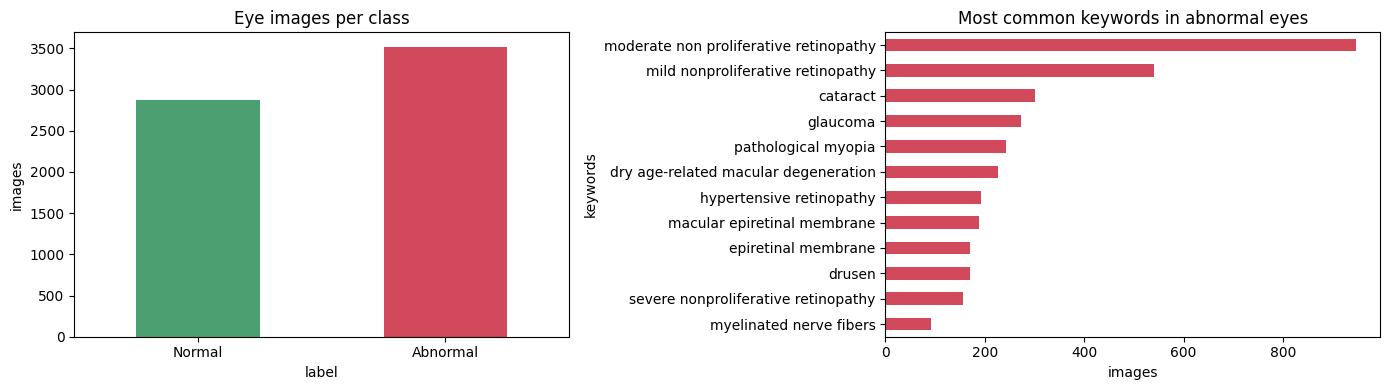

label
Abnormal    0.55
Normal      0.45


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
eyes['label'].value_counts().reindex(CLASS_NAMES).plot.bar(ax=ax[0], color=['#4C9F70', '#D1495B'])
ax[0].set_title('Eye images per class'); ax[0].set_ylabel('images'); ax[0].tick_params(axis='x', rotation=0)

top = (eyes.loc[eyes.target == 1, 'keywords'].map(split_keywords).explode()
           .loc[lambda s: ~s.isin(ARTIFACTS | {'normal fundus'})].value_counts().head(12))
top[::-1].plot.barh(ax=ax[1], color='#D1495B')
ax[1].set_title('Most common keywords in abnormal eyes'); ax[1].set_xlabel('images')
plt.tight_layout(); plt.show()
print(eyes['label'].value_counts(normalize=True).round(3).to_string())

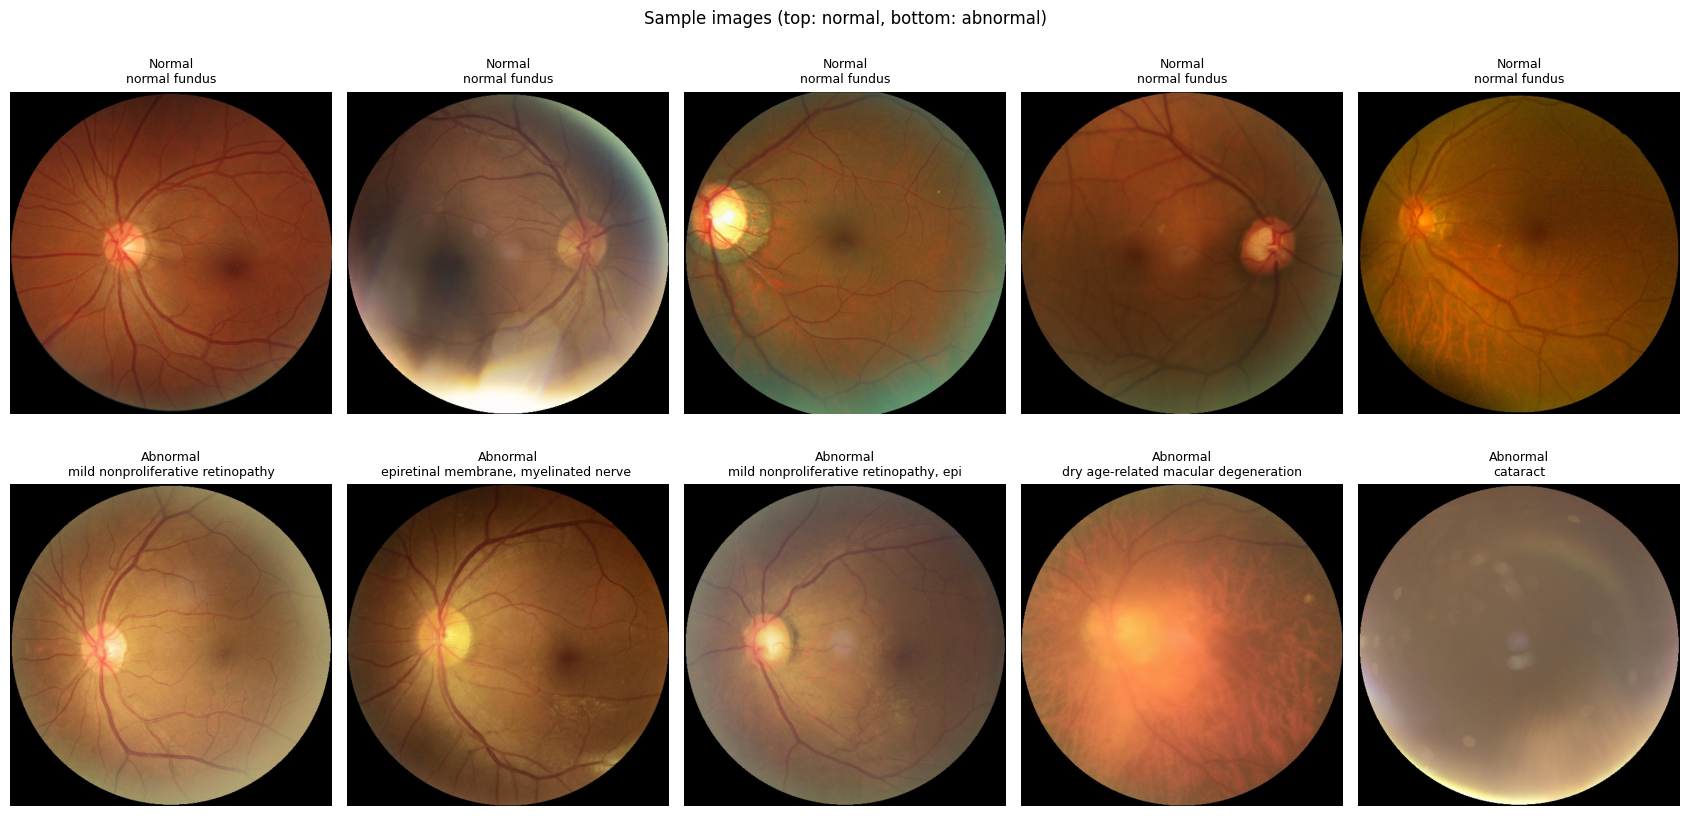

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(17, 8.8))
for row, cls in enumerate([0, 1]):
    sample = eyes[eyes.target == cls].sample(5, random_state=SEED)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        ax.imshow(Image.open(r['file_path']))
        ax.set_title(f"{CLASS_NAMES[cls]}\n{r['keywords'][:38]}", fontsize=9)
        ax.axis('off')
plt.suptitle('Sample images (top: normal, bottom: abnormal)'); plt.tight_layout(); plt.show()

## 3. Patient-level split (60 / 20 / 20)

Both eyes of a patient look alike: same person, same camera, and often the same disease. If one eye is in train and the other in test, the test score is inflated. `StratifiedGroupKFold` puts every patient in exactly one split and keeps the class ratio similar in all three.

In [7]:
def group_split(df, n_splits, seed):
    """Hold out ~1/n_splits of the rows, grouped by patient ID and stratified by target."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    keep_idx, hold_idx = next(sgkf.split(df, df['target'], groups=df['ID']))
    return df.iloc[keep_idx].reset_index(drop=True), df.iloc[hold_idx].reset_index(drop=True)

trainval_df, test_df = group_split(eyes, 5, SEED)          # 80 / 20
train_df, val_df     = group_split(trainval_df, 4, SEED)   # 60 / 20 of the total

assert not set(train_df.ID) & set(val_df.ID),  'patient leakage train/val'
assert not set(train_df.ID) & set(test_df.ID), 'patient leakage train/test'
assert not set(val_df.ID) & set(test_df.ID),   'patient leakage val/test'

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{name:5s}: {len(d):5d} images | {d.ID.nunique():4d} patients | abnormal = {d.target.mean():.1%}')
print('No patient appears in more than one split.')

train:  3821 images | 2015 patients | abnormal = 55.5%
val  :  1289 images |  671 patients | abnormal = 53.3%
test :  1281 images |  671 patients | abnormal = 55.6%
No patient appears in more than one split.


## 4. Datasets, augmentation and loaders

In [8]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics

train_tfms = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),            # left and right eyes are mirror images of each other
    T.RandomVerticalFlip(),
    T.RandomRotation(30),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.03),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.08)),   # hide a small patch so no single spot decides
])
eval_tfms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

class FundusDataset(Dataset):
    def __init__(self, df, transform):
        self.paths     = df['file_path'].tolist()
        self.targets   = df['target'].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.transform(img), self.targets[i]

def make_loader(df, tfms, shuffle):
    return DataLoader(FundusDataset(df, tfms), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'),
                      drop_last=shuffle, persistent_workers=NUM_WORKERS > 0)

train_loader = make_loader(train_df, train_tfms, shuffle=True)
val_loader   = make_loader(val_df,   eval_tfms,  shuffle=False)
test_loader  = make_loader(test_df,  eval_tfms,  shuffle=False)
print(f'{len(train_loader)} train / {len(val_loader)} val / {len(test_loader)} test batches of {BATCH_SIZE}')

119 train / 41 val / 41 test batches of 32


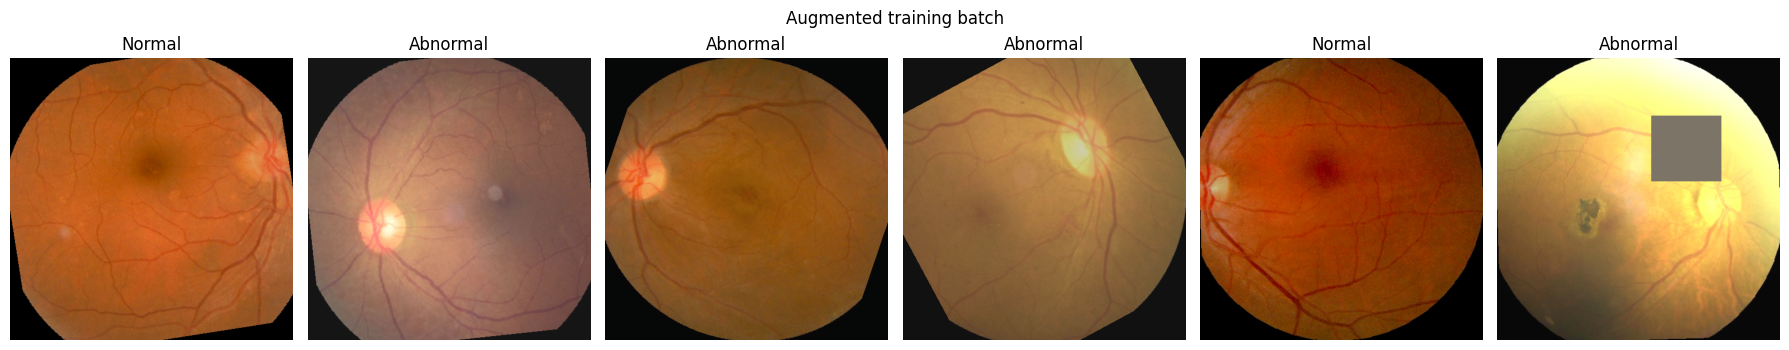

In [9]:
def denorm(t):
    """Normalised CHW tensor -> HWC numpy image in [0, 1] for plotting."""
    return (t.permute(1, 2, 0).cpu().numpy() * STD + MEAN).clip(0, 1)

xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax in axes: ax.axis('off')
for ax, img, lab in zip(axes, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(CLASS_NAMES[int(lab)]); ax.axis('off')
plt.suptitle('Augmented training batch'); plt.tight_layout(); plt.show()

## 5. Model: EfficientNet-B0 pretrained on ImageNet

The 1000-class ImageNet head is replaced with `Dropout(0.5) → Linear(1280, 2)`. The loss is cross-entropy with class weights, so the smaller class counts more, plus light label smoothing.

In [10]:
def build_model(pretrained=True):
    weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    try:
        model = efficientnet_b0(weights=weights)
    except Exception as e:
        raise RuntimeError('Could not download the ImageNet weights. On Kaggle turn on '
                           'Settings -> Internet, then re-run this cell.') from e
    in_features = model.classifier[1].in_features          # 1280
    model.classifier = nn.Sequential(nn.Dropout(p=DROPOUT), nn.Linear(in_features, len(CLASS_NAMES)))
    return model.to(device)

model = build_model()
print(f'EfficientNet-B0: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters')

counts = np.bincount(train_df['target'], minlength=len(CLASS_NAMES))
class_weights = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
print('train counts:', dict(zip(CLASS_NAMES, counts.tolist())),
      '| class weights:', class_weights.cpu().numpy().round(3).tolist())

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 111MB/s]


EfficientNet-B0: 4.01M parameters
train counts: {'Normal': 1702, 'Abnormal': 2119} | class weights: [1.1230000257492065, 0.9020000100135803]


## 6. Training

- **Stage 1** (`FROZEN_EPOCHS`): the pretrained backbone is frozen and only the new head learns, so its random weights don't damage the pretrained features.
- **Stage 2** (`FINETUNE_EPOCHS`): everything is unfrozen. The backbone gets a 10× smaller learning rate than the head, both decay on a cosine schedule, and training stops early when validation AUC stops improving.
- **Mixup** (both stages): in `MIXUP_PROB` of the training batches, each image is blended with another one, and the loss is blended in the same proportion. This stops the model from memorising individual training images. Training AUC is measured against each blended image's dominant label, so it is noisier and lower than validation AUC. That is expected.

The weights with the best validation AUC are saved to `best_model.pt`. If two epochs tie on AUC, the one with the lower validation loss is kept.

In [11]:
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

def set_backbone_trainable(model, trainable):
    for p in model.features.parameters():
        p.requires_grad = trainable

def run_epoch(model, loader, optimizer=None):
    """One pass over `loader`. Trains when an optimizer is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train(training)
    if training and not next(model.features.parameters()).requires_grad:
        model.features.eval()            # frozen backbone: keep its BatchNorm statistics fixed
    total_loss, all_probs, all_targets = 0.0, [], []
    for x, y in tqdm(loader, leave=False, desc='train' if training else 'eval'):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        lam, y_b = 1.0, y
        if training and MIXUP_ALPHA > 0 and np.random.rand() < MIXUP_PROB:
            lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
            lam = max(lam, 1 - lam)                    # keep y as the dominant label
            perm = torch.randperm(x.size(0), device=x.device)
            x, y_b = lam * x + (1 - lam) * x[perm], y[perm]
        with torch.set_grad_enabled(training), torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
            loss = lam * criterion(logits, y) + (1 - lam) * criterion(logits, y_b)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * x.size(0)
        all_probs.append(torch.softmax(logits.float(), dim=1)[:, 1].detach().cpu())
        all_targets.append(y.cpu())
    probs, targets = torch.cat(all_probs).numpy(), torch.cat(all_targets).numpy()
    return total_loss / len(probs), roc_auc_score(targets, probs)

history = []
best_auc, best_loss, best_epoch, bad_epochs = -1.0, float('inf'), 0, 0
CKPT_PATH = OUT_DIR / 'best_model.pt'

def fit(optimizer, scheduler, epochs, stage):
    global best_auc, best_loss, best_epoch, bad_epochs
    for _ in range(epochs):
        t0 = time.time()
        tr_loss, tr_auc = run_epoch(model, train_loader, optimizer)
        va_loss, va_auc = run_epoch(model, val_loader)
        if scheduler is not None:
            scheduler.step()
        epoch = len(history) + 1
        history.append(dict(epoch=epoch, stage=stage, train_loss=tr_loss, val_loss=va_loss,
                            train_auc=tr_auc, val_auc=va_auc))
        # higher validation AUC wins; if AUC ties, the lower validation loss wins
        improved = va_auc > best_auc or (va_auc == best_auc and va_loss < best_loss)
        if improved:
            best_auc, best_loss, best_epoch, bad_epochs = va_auc, va_loss, epoch, 0
            torch.save(model.state_dict(), CKPT_PATH)
        else:
            bad_epochs += 1
        print(f'[{stage:8s}] epoch {epoch:2d} | train loss {tr_loss:.4f} auc {tr_auc:.4f} | '
              f'val loss {va_loss:.4f} auc {va_auc:.4f} | {time.time() - t0:4.0f}s'
              + ('  <- best, saved' if improved else ''))
        if stage == 'finetune' and bad_epochs >= PATIENCE:
            print(f'Early stopping: validation AUC has not improved for {PATIENCE} epochs.')
            break

In [12]:
# Stage 1: backbone frozen, only the classifier head is trained
set_backbone_trainable(model, False)
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
fit(optimizer, None, FROZEN_EPOCHS, stage='frozen')

train:   0%|          | 0/119 [00:01<?, ?it/s]

eval:   0%|          | 0/41 [00:00<?, ?it/s]

[frozen  ] epoch  1 | train loss 0.6728 auc 0.6311 | val loss 0.6316 auc 0.7222 |   91s  <- best, saved


train:   0%|          | 0/119 [00:00<?, ?it/s]

eval:   0%|          | 0/41 [00:00<?, ?it/s]

[frozen  ] epoch  2 | train loss 0.6461 auc 0.6862 | val loss 0.6339 auc 0.7271 |   67s  <- best, saved


train:   0%|          | 0/119 [00:00<?, ?it/s]

eval:   0%|          | 0/41 [00:00<?, ?it/s]

[frozen  ] epoch  3 | train loss 0.6420 auc 0.6942 | val loss 0.6105 auc 0.7391 |   67s  <- best, saved


In [13]:
# Stage 2: unfreeze everything; small LR for the pretrained backbone, cosine decay
set_backbone_trainable(model, True)
optimizer = torch.optim.AdamW([
    {'params': model.features.parameters(),   'lr': LR_BACKBONE},
    {'params': model.classifier.parameters(), 'lr': LR_HEAD},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6)
bad_epochs = 0
fit(optimizer, scheduler, FINETUNE_EPOCHS, stage='finetune')
print(f'\nBest validation AUC {best_auc:.4f} at epoch {best_epoch}')

train:   0%|          | 0/119 [00:00<?, ?it/s]

eval:   0%|          | 0/41 [00:00<?, ?it/s]

[finetune] epoch  4 | train loss 0.6686 auc 0.6518 | val loss 0.6061 auc 0.7414 |  122s  <- best, saved


train:   0%|          | 0/119 [00:00<?, ?it/s]

eval:   0%|          | 0/41 [00:00<?, ?it/s]

...

eval:   0%|          | 0/41 [00:00<?, ?it/s]

[finetune] epoch 31 | train loss 0.4202 auc 0.9290 | val loss 0.5080 auc 0.8492 |   77s


train:   0%|          | 0/119 [00:00<?, ?it/s]

eval:   0%|          | 0/41 [00:00<?, ?it/s]

[finetune] epoch 32 | train loss 0.4238 auc 0.9266 | val loss 0.5121 auc 0.8460 |   76s
Early stopping: validation AUC has not improved for 7 epochs.

Best validation AUC 0.8526 at epoch 25


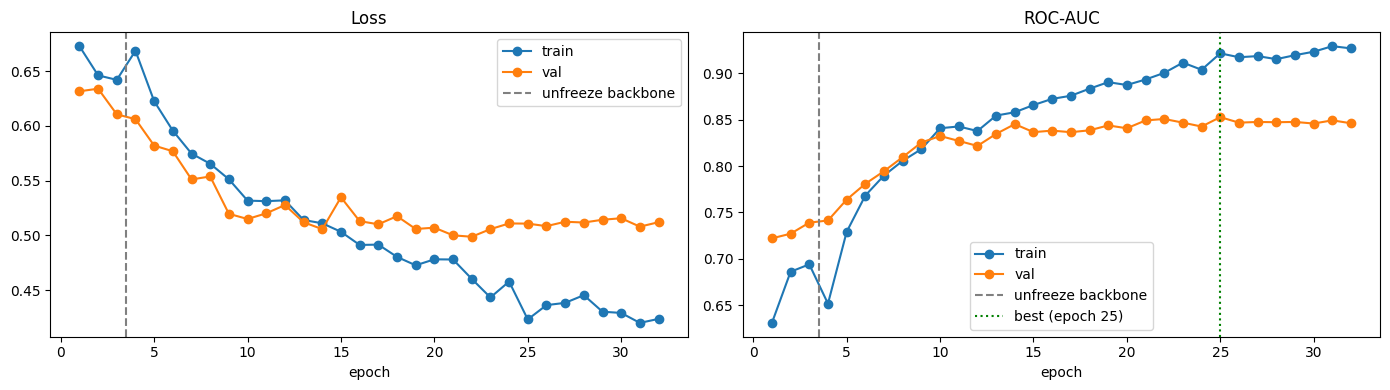

In [14]:
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], 'loss', 'Loss'), (ax[1], 'auc', 'ROC-AUC')]:
    a.plot(hist.epoch, hist[f'train_{col}'], 'o-', label='train')
    a.plot(hist.epoch, hist[f'val_{col}'], 'o-', label='val')
    a.axvline(FROZEN_EPOCHS + 0.5, ls='--', c='gray', label='unfreeze backbone')
    a.set_title(title); a.set_xlabel('epoch')
ax[1].axvline(best_epoch, ls=':', c='green', label=f'best (epoch {best_epoch})')
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / 'training_curves.png', dpi=120); plt.show()

## 7. Evaluation on the held-out test set

The best checkpoint is reloaded. Predictions average the original image and its horizontal flip (test-time augmentation). The decision threshold is tuned **on validation only**, using Youden's J (sensitivity + specificity − 1), and then applied unchanged to test. Test results are shown at three thresholds: the default 0.5; Youden's threshold, which is used for the plots and `predict()`; and the highest threshold that still catches `TARGET_SENSITIVITY` (85%) of abnormal eyes on validation. That last one is a common choice for screening, where missing disease costs more than a false alarm. *Positive class = Abnormal*, so sensitivity is the share of diseased eyes the model catches.

In [15]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
model.eval()

@torch.no_grad()
def predict_probs(model, loader, tta=True):
    probs = []
    for x, _ in tqdm(loader, leave=False, desc='predict'):
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            p = torch.softmax(model(x).float(), dim=1)[:, 1]
            if tta:   # average with the horizontally flipped image
                p = (p + torch.softmax(model(torch.flip(x, dims=[3])).float(), dim=1)[:, 1]) / 2
        probs.append(p.float().cpu())
    return torch.cat(probs).numpy()

val_probs  = predict_probs(model, val_loader)
test_probs = predict_probs(model, test_loader)
y_val, y_test = val_df['target'].values, test_df['target'].values

fpr, tpr, thr = roc_curve(y_val, val_probs)
best_thr = float(np.clip(thr[np.argmax(tpr - fpr)], 0.0, 1.0))                # Youden's J
sens_thr = float(np.clip(thr[np.argmax(tpr >= TARGET_SENSITIVITY)], 0.0, 1.0))  # highest threshold reaching the target
print(f'Validation AUC (with TTA): {roc_auc_score(y_val, val_probs):.4f} | '
      f"Youden threshold: {best_thr:.3f} | {TARGET_SENSITIVITY:.0%}-sensitivity threshold: {sens_thr:.3f}")

def metrics(y_true, probs, threshold):
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'threshold':   round(threshold, 3),
            'accuracy':    accuracy_score(y_true, pred),
            'roc_auc':     roc_auc_score(y_true, probs),
            'pr_auc':      average_precision_score(y_true, probs),
            'f1_abnormal': f1_score(y_true, pred, zero_division=0),
            'sensitivity': tp / max(tp + fn, 1),   # abnormal eyes correctly flagged
            'specificity': tn / max(tn + fp, 1)}   # normal eyes correctly cleared

results = pd.DataFrame([metrics(y_test, test_probs, 0.5), metrics(y_test, test_probs, best_thr),
                        metrics(y_test, test_probs, sens_thr)],
                       index=['test @ 0.5', 'test @ Youden threshold',
                              f'test @ {TARGET_SENSITIVITY:.0%}-sensitivity threshold']).round(4)
results.to_csv(OUT_DIR / 'test_metrics.csv')
display(results)
print(classification_report(y_test, (test_probs >= best_thr).astype(int),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))

predict:   0%|          | 0/41 [00:00<?, ?it/s]

predict:   0%|          | 0/41 [00:00<?, ?it/s]

Validation AUC (with TTA): 0.8577 | Youden threshold: 0.519 | 85%-sensitivity threshold: 0.217


,threshold,accuracy,roc_auc,pr_auc,f1_abnormal,sensitivity,specificity
test @ 0.5,0.500,0.7721,0.8609,0.8977,0.7694,0.6840,0.8822
test @ Youden threshold,0.519,0.7728,0.8609,0.8977,0.7678,0.6756,0.8946
test @ 85%-sensitivity threshold,0.217,0.7471,0.8609,0.8977,0.7926,0.8694,0.5940


              precision    recall  f1-score   support

      Normal     0.6878    0.8946    0.7777       569
    Abnormal     0.8891    0.6756    0.7678       712

    accuracy                         0.7728      1281
   macro avg     0.7885    0.7851    0.7727      1281
weighted avg     0.7997    0.7728    0.7722      1281



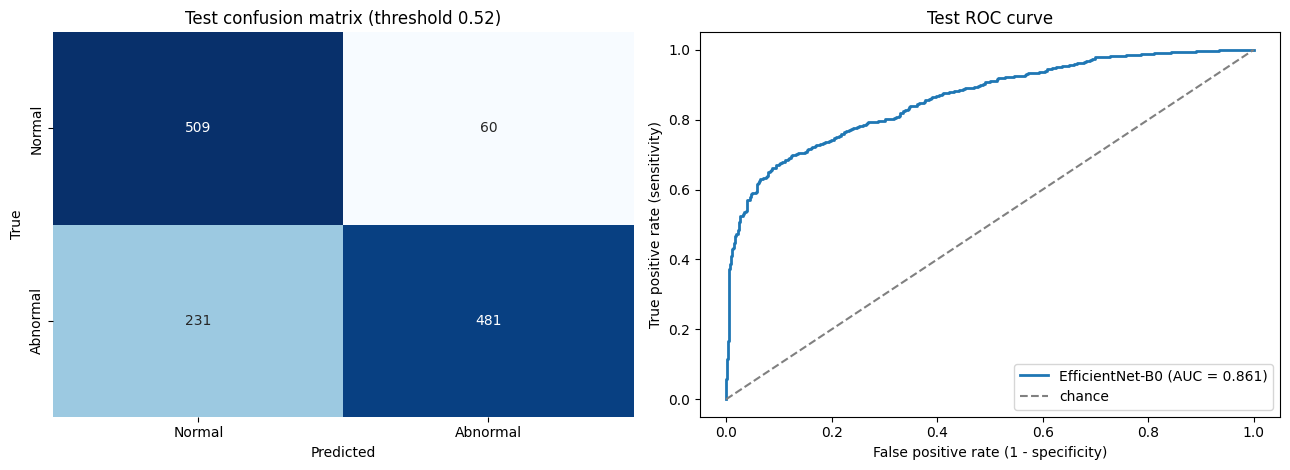

In [16]:
test_pred = (test_probs >= best_thr).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('True')
ax[0].set_title(f'Test confusion matrix (threshold {best_thr:.2f})')

fpr_t, tpr_t, _ = roc_curve(y_test, test_probs)
ax[1].plot(fpr_t, tpr_t, lw=2, label=f'EfficientNet-B0 (AUC = {roc_auc_score(y_test, test_probs):.3f})')
ax[1].plot([0, 1], [0, 1], '--', c='gray', label='chance')
ax[1].set_xlabel('False positive rate (1 - specificity)'); ax[1].set_ylabel('True positive rate (sensitivity)')
ax[1].set_title('Test ROC curve'); ax[1].legend(loc='lower right')
plt.tight_layout(); plt.savefig(OUT_DIR / 'test_evaluation.png', dpi=120); plt.show()

In [17]:
# Save per-image test predictions and a self-contained checkpoint
preds = test_df[['ID', 'eye', 'file_path', 'keywords', 'target']].copy()
preds['prob_abnormal'] = test_probs
preds['pred'] = test_pred
preds.to_csv(OUT_DIR / 'test_predictions.csv', index=False)

torch.save({'state_dict': model.state_dict(), 'threshold': best_thr, 'img_size': IMG_SIZE,
            'class_names': CLASS_NAMES, 'arch': 'efficientnet_b0'}, OUT_DIR / 'odir_effnetb0_final.pt')
print('Saved:', sorted(p.name for p in OUT_DIR.iterdir() if p.suffix in {'.pt', '.csv', '.png'}))

Saved: ['best_model.pt', 'odir_effnetb0_final.pt', 'test_evaluation.png', 'test_metrics.csv', 'test_predictions.csv', 'training_curves.png']


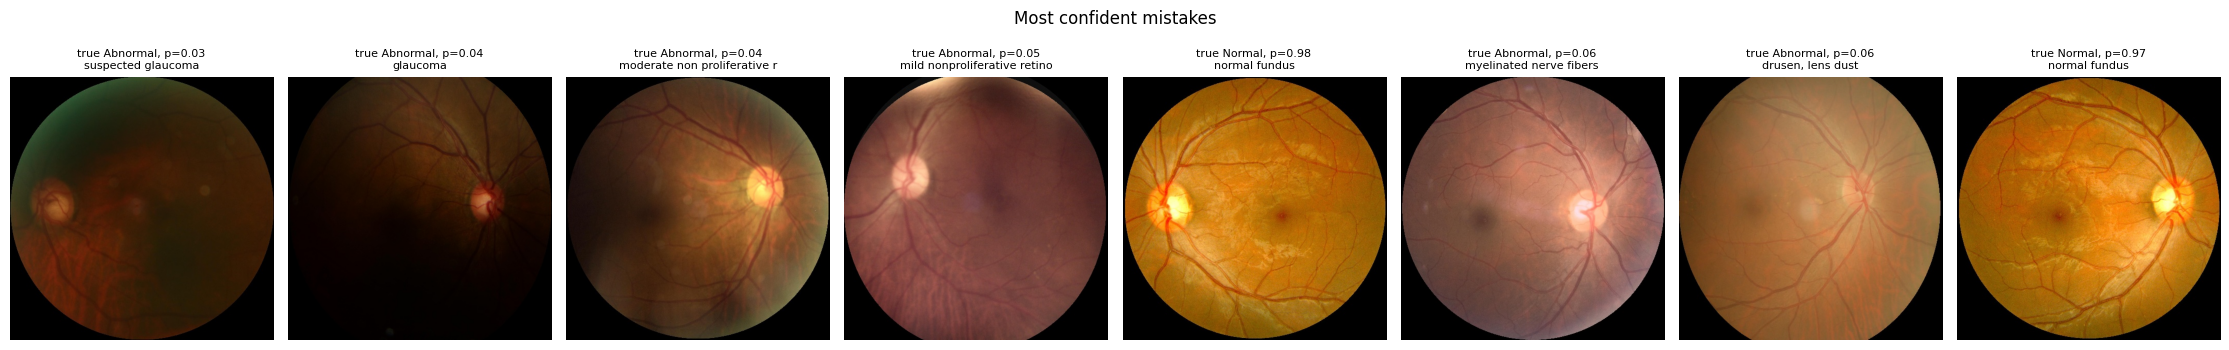

In [18]:
# Error analysis: the test images the model got most confidently wrong
wrong = (preds[preds.pred != preds.target]
         .assign(margin=lambda d: (d.prob_abnormal - best_thr).abs())
         .sort_values('margin', ascending=False).head(8))
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.8 * len(wrong), 3.8), squeeze=False)
    for ax, (_, r) in zip(axes[0], wrong.iterrows()):
        ax.imshow(Image.open(r['file_path'])); ax.axis('off')
        ax.set_title(f"true {CLASS_NAMES[r['target']]}, p={r['prob_abnormal']:.2f}\n{r['keywords'][:28]}", fontsize=8)
    plt.suptitle('Most confident mistakes'); plt.tight_layout(); plt.show()
else:
    print('No mistakes on the test set.')

## 8. Grad-CAM: where is the model looking?

Grad-CAM weights the last convolutional feature maps by their gradient with respect to the model's *Abnormal vs Normal* score (the log-odds). Warm regions pushed the prediction towards *Abnormal*. On abnormal eyes they should sit on lesions, the optic disc, or the macula, not on the black border.

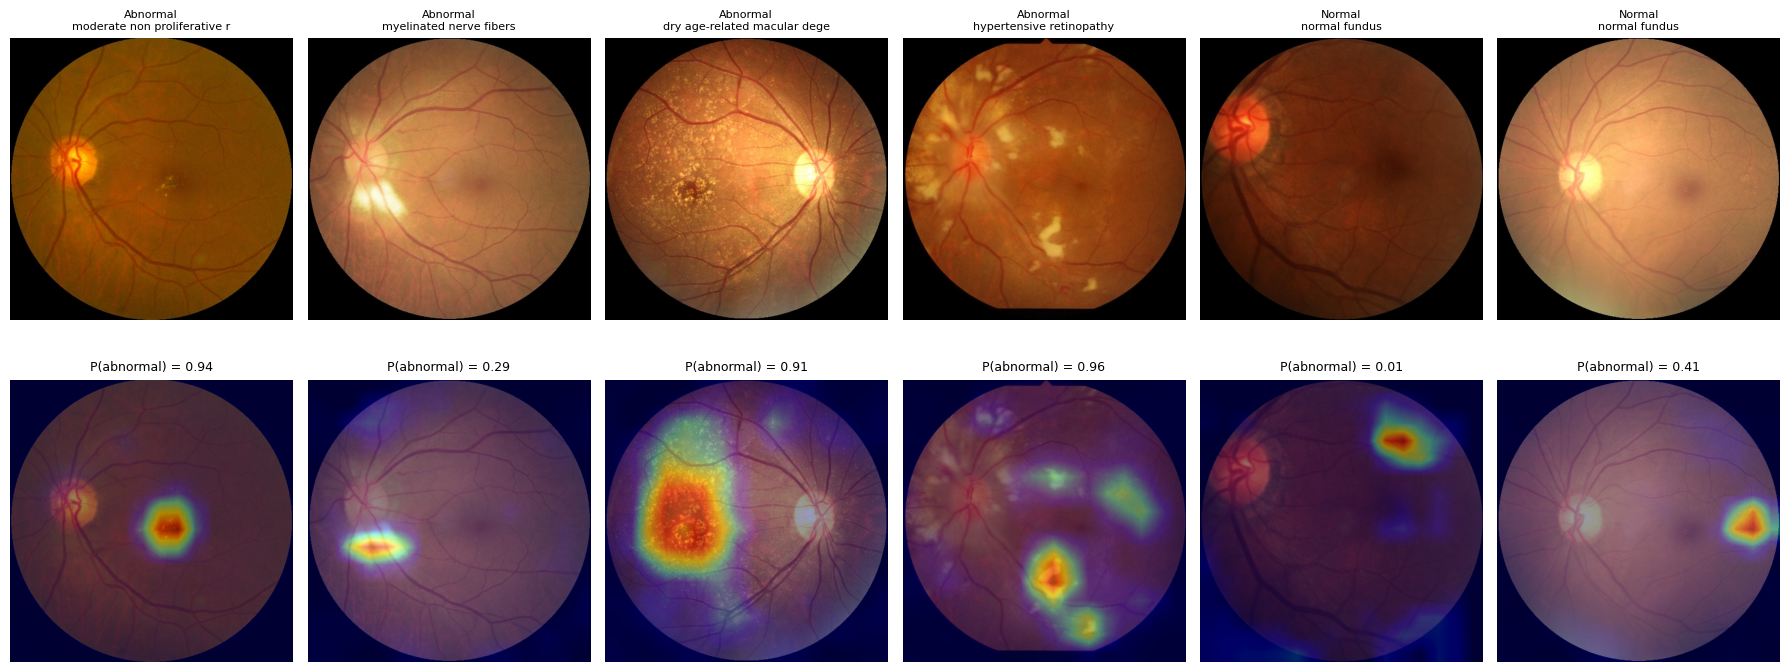

In [19]:
class GradCAM:
    """Grad-CAM on a conv layer (here the last EfficientNet block, model.features[-1])."""
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._save)

    def _save(self, module, inputs, output):
        self.acts = output
        if output.requires_grad:
            output.register_hook(lambda g: setattr(self, 'grads', g))

    def __call__(self, x):
        self.model.eval()
        with torch.enable_grad():
            logits = self.model(x)
            self.model.zero_grad(set_to_none=True)
            (logits[:, 1] - logits[:, 0]).sum().backward()   # log-odds of Abnormal vs Normal
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0]
        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        probs = torch.softmax(logits.float(), dim=1)[:, 1]
        return cam.detach().cpu().numpy(), probs.detach().cpu().numpy()

    def remove(self):
        self.handle.remove()

cam_tool = GradCAM(model, model.features[-1])
picks = pd.concat([test_df[test_df.target == 1].sample(4, random_state=1),
                   test_df[test_df.target == 0].sample(2, random_state=1)])
x = torch.stack([eval_tfms(Image.open(p).convert('RGB')) for p in picks.file_path]).to(device)
cams, probs = cam_tool(x)
cam_tool.remove()

fig, axes = plt.subplots(2, len(picks), figsize=(3 * len(picks), 7.4))
for i, (_, r) in enumerate(picks.iterrows()):
    img = denorm(x[i])
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"{CLASS_NAMES[r['target']]}\n{r['keywords'][:28]}", fontsize=8)
    axes[1, i].imshow(img); axes[1, i].imshow(cams[i], cmap='jet', alpha=0.4)
    axes[1, i].set_title(f'P(abnormal) = {probs[i]:.2f}', fontsize=9)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'gradcam.png', dpi=120); plt.show()

## 9. Using the model on new images

In [20]:
def predict(image_path, threshold=best_thr):
    """Classify one fundus image. Returns P(abnormal) and the predicted label."""
    model.eval()
    x = eval_tfms(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        p = (torch.softmax(model(x), 1)[0, 1] + torch.softmax(model(torch.flip(x, dims=[3])), 1)[0, 1]) / 2
    p = float(p)
    return {'file': Path(image_path).name, 'prob_abnormal': round(p, 4),
            'prediction': CLASS_NAMES[int(p >= threshold)]}

for _, r in test_df.sample(4, random_state=0).iterrows():
    print(predict(r['file_path']), '| true:', CLASS_NAMES[r['target']])

{'file': '3182_right.jpg', 'prob_abnormal': 0.224, 'prediction': 'Normal'} | true: Normal
{'file': '2498_right.jpg', 'prob_abnormal': 0.4997, 'prediction': 'Normal'} | true: Normal
{'file': '1850_left.jpg', 'prob_abnormal': 0.9291, 'prediction': 'Abnormal'} | true: Abnormal
{'file': '614_left.jpg', 'prob_abnormal': 0.4361, 'prediction': 'Normal'} | true: Abnormal


In [21]:
# Reloading the saved model later, e.g. in another notebook
ckpt = torch.load(OUT_DIR / 'odir_effnetb0_final.pt', map_location=device)
reloaded = efficientnet_b0(weights=None)
reloaded.classifier = nn.Sequential(nn.Dropout(p=DROPOUT), nn.Linear(1280, len(ckpt['class_names'])))
reloaded.load_state_dict(ckpt['state_dict'])
reloaded = reloaded.to(device).eval()
print('Reloaded', ckpt['arch'], '| threshold', round(ckpt['threshold'], 3), '| image size', ckpt['img_size'])

Reloaded efficientnet_b0 | threshold 0.519 | image size 512


## 10. Notes and next steps

- **Reading the numbers:** report **ROC-AUC**, **sensitivity** and **specificity** from the test set, not training accuracy. For screening, a missed disease (false negative) usually costs more than a false alarm. To favour sensitivity, choose a lower threshold on the validation ROC curve.
- **Getting more accuracy:**
  - Train at a higher resolution (448–512).
  - Use a bigger backbone (`efficientnet_b3`, or `convnext_tiny` via `timm`).
  - Train for longer with stronger augmentation.
  - Run 5-fold `StratifiedGroupKFold` cross-validation and average the fold models.
- **Going further:** turn this into an 8-label, per-eye classifier (N, D, G, C, A, H, M, O) by mapping each eye's keywords to those categories, and use `BCEWithLogitsLoss` with one sigmoid output per disease.
- **Limitations:** the labels come from free-text keywords, so some are noisy. ODIR images come from several cameras and hospitals in China, so performance on other populations or devices must be checked separately.